# Project 4 – Product Monitoring Book: Python analysis

**Source:** `data/Project4_ProductMonitoringBook.xlsx` (we only read it; we never change it).

**What the workbook contains:** a BOST *Daily BDC Transfer Report*. There is one sheet per working day (742 sheets), and each lists how much fuel every Bulk Distribution Company (BDC) moved:

| Column | Meaning |
|---|---|
| BDC LIST | The Bulk Distribution Company |
| KSI_AGO, KSI_PMS | Liftings at the **Kumasi** depot: AGO (diesel) and PMS (petrol) |
| BUIPE_AGO, BUIPE_PMS | Transfers through the **Buipe** depot |
| AKOSOMBO_AGO | Transfers through the **Akosombo** depot (diesel only) |
| DATE | Report date (copied from cell G3) |

A **Combined** sheet stacks all daily tables with a Power Query append. A **Summary** pivot and a **Dashboard** are built on Combined. The workbook never states a unit; the volumes look like litres.

### Business questions
1. **BQ1 Volume and mix:** how much moved, through which depot, and what was the AGO vs PMS mix?
2. **BQ2 Concentration:** how concentrated is volume among BDCs?
3. **BQ3 Trend:** is volume growing or shrinking, and which months stand out?
4. **BQ4 Customer shifts:** which BDCs are growing, declining or dormant?
5. **BQ5 Reliability:** can management trust the Summary and Dashboard?

This notebook rebuilds the clean data from the source workbook and checks that it matches the clean table in the Excel analysis workbook.

In [1]:
# Import the libraries we need
import os
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Paths (relative to this notebooks/ folder)
file = "../data/Project4_ProductMonitoringBook.xlsx"
clean_csv = "../data/Project4_ProductMonitoring_CleanData_final.csv"

# The five volume columns
vols = ["KSI_AGO", "KSI_PMS", "BUIPE_AGO", "BUIPE_PMS", "AKOSOMBO_AGO"]

## 1. Understand the workbook

In [2]:
# List the sheets
x = pd.ExcelFile(file)
print("Sheets:", len(x.sheet_names))
print(x.sheet_names[:4], "...", x.sheet_names[-3:])

# Everything except Summary, Combined and BDC List is a daily report
daily_names = [n for n in x.sheet_names if n not in ("Summary", "Combined", "BDC List")]
print("Daily sheets:", len(daily_names))

Sheets: 745
['Summary', 'Combined', '09-09-2020 ', '10-09-2020 '] ... ['04-09-2023', '05-09-2023', 'BDC List']
Daily sheets: 742


In [3]:
# Look at one daily sheet as it appears in Excel (no header yet)
pd.read_excel(x, sheet_name=daily_names[0], header=None, nrows=22)

,0,1,2,3,4,5,6,7
0,NaN,BOST,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,TRANSMISSIONS UNIT - APD,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,DAILY BDC TRANSFER REPORT,NaN,NaN,NaN,DATE,2020-09-09 00:00:00,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,BDC LIST,KSI_AGO,KSI_PMS,BUIPE_AGO,BUIPE_PMS,AKOSOMBO_AGO,DATE
5,NaN,Alfa Petroleum,NaN,NaN,NaN,NaN,NaN,2020-09-09 00:00:00
6,NaN,Astra Oil Services Limited,NaN,NaN,NaN,NaN,NaN,2020-09-09 00:00:00
7,NaN,Blue Ocean,432000,NaN,NaN,NaN,NaN,2020-09-09 00:00:00
8,NaN,BOST,NaN,374000,NaN,797000,NaN,2020-09-09 00:00:00
9,NaN,Chase Petroleum,245000,NaN,NaN,NaN,NaN,2020-09-09 00:00:00


In [4]:
# The Summary pivot: total volume per volume column (this is what management sees)
summary = pd.read_excel(x, sheet_name="Summary", header=4, usecols="A:F")
summary[summary["Row Labels"] == "Grand Total"]

c:\heartDiseaseProject\env\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
c:\heartDiseaseProject\env\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


,Row Labels,Sum of KSI_AGO,Sum of KSI_PMS,Sum of BUIPE_AGO,Sum of BUIPE_PMS,Sum of AKOSOMBO_AGO
21,Grand Total,1.268988e+09,1.059796e+09,298099000.0,284674500.0,146206000.0


## 2. Load the data

In [5]:
# Read every daily sheet in one go. The table header is on row 5 (header=4), columns B:H.
sheets = pd.read_excel(x, sheet_name=daily_names, header=4, usecols="B:H")

# Each table ends with a "Total" row followed by a totals block. Keep only the rows above "Total".
parts = []
for name, table in sheets.items():
    total_row = table.index[table["BDC LIST"] == "Total"][0]
    table = table.iloc[:total_row].copy()
    table["SHEET"] = name
    parts.append(table)

daily = pd.concat(parts, ignore_index=True)
print("Rows from the daily sheets:", len(daily))
daily.head()

Rows from the daily sheets: 12547


,BDC LIST,KSI_AGO,KSI_PMS,BUIPE_AGO,BUIPE_PMS,AKOSOMBO_AGO,DATE,SHEET
0,Alfa Petroleum,NaN,NaN,NaN,NaN,NaN,2020-09-09,09-09-2020
1,Astra Oil Services Limited,NaN,NaN,NaN,NaN,NaN,2020-09-09,09-09-2020
2,Blue Ocean,432000,NaN,NaN,NaN,NaN,2020-09-09,09-09-2020
3,BOST,NaN,374000.0,NaN,797000.0,NaN,2020-09-09,09-09-2020
4,Chase Petroleum,245000,NaN,NaN,NaN,NaN,2020-09-09,09-09-2020


In [6]:
# The Combined sheet (the Power Query output that feeds the Summary and Dashboard)
comb = pd.read_excel(x, sheet_name="Combined")
print("Combined rows:", len(comb))
comb.head()

Combined rows: 14943


,BDC LIST,KSI_AGO,KSI_PMS,BUIPE_AGO,BUIPE_PMS,AKOSOMBO_AGO,DATE,Year,Month Name
0,Alfa Petroleum,NaN,NaN,NaN,NaN,NaN,2020-01-03 00:00:00,2020,January
1,Astra Oil Services Limited,NaN,NaN,NaN,NaN,NaN,2020-01-03 00:00:00,2020,January
2,Blue Ocean,NaN,NaN,NaN,NaN,NaN,2020-01-03 00:00:00,2020,January
3,BOST,NaN,NaN,NaN,NaN,NaN,2020-01-03 00:00:00,2020,January
4,Chase Petroleum,NaN,54000.0,NaN,NaN,NaN,2020-01-03 00:00:00,2020,January


## 3. Validate the data

In [7]:
# Check 1: Combined's DATE column mixes real dates with plain numbers (Excel date serials)
serial = pd.to_numeric(comb["DATE"], errors="coerce")
print("DATE cells stored as numbers instead of dates:", serial.notna().sum())

# Turn both kinds into proper dates (Excel counts days from 30 Dec 1899)
as_date = pd.to_datetime(comb["DATE"].where(serial.isna()))
comb["DATE"] = pd.to_datetime(serial, unit="D", origin="1899-12-30").fillna(as_date)
print(comb["DATE"].min(), "to", comb["DATE"].max())

DATE cells stored as numbers instead of dates: 11371
2020-01-03 00:00:00 to 2023-08-31 00:00:00


In [8]:
# Check 2: does the date in cell G3 (DATE column) match the date in the sheet name?
daily["SHEET_DATE"] = pd.to_datetime(daily["SHEET"].str.strip(), format="%d-%m-%Y", errors="coerce")
print("Sheet names that are not dd-mm-yyyy:", daily[daily["SHEET_DATE"].isna()]["SHEET"].unique())

wrong_date = daily[daily["SHEET_DATE"].notna() & (daily["SHEET_DATE"] != daily["DATE"])]
print("Sheets whose G3 date was not updated after copying:", wrong_date["SHEET"].nunique(), "| rows:", len(wrong_date))
wrong_date.groupby("SHEET")[["SHEET_DATE", "DATE"]].first()

Sheet names that are not dd-mm-yyyy: <StringArray>
['23-04-20']
Length: 1, dtype: str
Sheets whose G3 date was not updated after copying: 9 | rows: 159


,SHEET_DATE,DATE
SHEET,,
02-06-2023,2023-06-02,2023-06-03
03-09-2021,2021-09-03,2021-09-02
09-09-2022,2022-09-09,2022-09-08
11-10-2022,2022-10-11,2022-10-10
14-09-2022,2022-09-14,2022-09-13
21-02-2022,2022-02-21,2022-02-18
24-02-2022,2022-02-24,2022-02-25
24-05-2022,2022-05-24,2022-05-23
31-03-2023,2023-03-31,2023-03-30


In [9]:
# Check 3: two sheets for the same day? (sheet names that differ only by a trailing space)
print("Sheet names with a trailing space:", sum(n != n.strip() for n in daily_names))
same_day = daily.groupby(daily["SHEET"].str.strip())["SHEET"].nunique()
same_day[same_day > 1]

Sheet names with a trailing space: 43


SHEET
03-06-2022    2
19-08-2022    2
Name: SHEET, dtype: int64

In [10]:
# Check 4: text inside the number columns, negative values and blank cells
for col in vols:
    numbers = pd.to_numeric(daily[col], errors="coerce")
    text = daily[col][numbers.isna() & daily[col].notna()]
    print(col, "| text values:", text.unique(), "| negatives:", (numbers < 0).sum())
print("Daily-sheet rows with no movement at all (all blank):", daily[vols].isna().all(axis=1).sum())

KSI_AGO | text values: [] | negatives: 0
KSI_PMS | text values: [] | negatives: 0
BUIPE_AGO | text values: [] | negatives: 0
BUIPE_PMS | text values: [] | negatives: 0
AKOSOMBO_AGO | text values: ['`'] | negatives: 0
Daily-sheet rows with no movement at all (all blank): 7972


In [11]:
# Check 5: BDC names with stray spaces
print("Rows with a leading/trailing space in the BDC name:", (daily["BDC LIST"] != daily["BDC LIST"].str.strip()).sum())
daily[daily["BDC LIST"] != daily["BDC LIST"].str.strip()]["BDC LIST"].unique()

Rows with a leading/trailing space in the BDC name: 742


<StringArray>
['Lemla Petroleum ']
Length: 1, dtype: str

In [12]:
# Check 6: is Combined up to date with the daily sheets?
first_sheet_date = daily["DATE"].min()
comb_only = comb[comb["DATE"] < first_sheet_date]
print("Combined rows dated before the first daily sheet (no source sheet):", len(comb_only),
      "| volume:", f"{comb_only[vols].sum().sum():,.0f}")

# Combined uses the G3 date (DATE column), so compare on that
missing_days = sorted(set(daily["DATE"]) - set(comb["DATE"]))
missing = daily[daily["DATE"].isin(missing_days)]
print("Daily sheets not yet in Combined:", [d.date() for d in missing_days],
      "| volume:", f"{pd.to_numeric(missing[vols].stack(), errors='coerce').sum():,.0f}")

Combined rows dated before the first daily sheet (no source sheet): 2438 | volume: 618,103,000


Daily sheets not yet in Combined: [datetime.date(2023, 9, 4), datetime.date(2023, 9, 5)] | volume: 7,618,500


In [13]:
# Check 7: on the dates both have, does Combined equal the daily sheets?
daily_num = daily.copy()
daily_num[vols] = daily_num[vols].apply(pd.to_numeric, errors="coerce").fillna(0)
by_day_daily = daily_num.groupby("DATE")[vols].sum()
by_day_comb = comb.fillna({c: 0 for c in vols}).groupby("DATE")[vols].sum()
shared = by_day_daily.index.intersection(by_day_comb.index)
print("Shared dates:", len(shared), "| dates where totals differ:",
      (by_day_daily.loc[shared] != by_day_comb.loc[shared]).any(axis=1).sum())

Shared dates: 729 | dates where totals differ: 0


In [14]:
# Check 8: exact duplicate rows in the Combined-only part
print("Exact duplicate rows:", comb_only.duplicated().sum())
comb_only[comb_only.duplicated(keep=False)]

Exact duplicate rows: 1


,BDC LIST,KSI_AGO,KSI_PMS,BUIPE_AGO,BUIPE_PMS,AKOSOMBO_AGO,DATE,Year,Month Name
2368,Astra Oil Services Limited,NaN,NaN,NaN,NaN,NaN,2020-09-03,2020,September
2370,Astra Oil Services Limited,NaN,NaN,NaN,NaN,NaN,2020-09-03,2020,September


### Validation summary
* **Combined's DATE column is inconsistent:** 11,371 of its 14,943 dates are stored as plain Excel serial numbers, not as dates. They are converted to real dates.
* **9 daily sheets have the wrong date in G3** (159 rows). The sheet was copied but G3 was not updated, e.g. sheet `03-09-2021` says 2 September 2021. The date from the sheet name is used instead.
* **One sheet name has a 2-digit year** (`23-04-20`). Its G3 date (23 April 2021) is used.
* **Two reports for one day:** 03-06-2022 and 19-08-2022 each exist twice, as sheet names that differ only by a trailing space (43 sheet names have one). Both reports are kept and flagged.
* **One stray backtick** in a number column (AKOSOMBO_AGO, Goenergy, 21-05-2021) is set to 0. There are no negative values.
* **A trailing space in one BDC name**, "Lemla Petroleum " (918 rows after combining), is trimmed.
* **Combined is stale.** It holds 2,438 rows (3 Jan – 8 Sep 2020, 618,103,000) whose daily sheets are no longer in the workbook. These are kept and flagged. It also misses the 04-09-2023 and 05-09-2023 sheets (7,618,500), which are added.
* **On the 729 dates both share, Combined matches the daily sheets exactly.**
* **One exact duplicate row** (Astra, 3 Sep 2020, zero volume) is removed.
* Blank volume cells mean no movement that day and are set to 0.

## 4. Clean the data

In [15]:
# 1) Daily rows: take the date from the sheet name (it is right when G3 is wrong).
#    The one sheet named with a 2-digit year ("23-04-20") keeps its G3 date.
daily["Date"] = daily["SHEET_DATE"].fillna(daily["DATE"])
daily["Source"] = "Daily sheet"

# 2) Combined-only rows (Jan-Sep 2020): keep them, drop the exact duplicate, and flag them
old = comb_only.drop_duplicates().copy()
old["Date"] = old["DATE"]
old["SHEET"] = "Combined"
old["Source"] = "Combined only (daily sheet no longer in workbook)"

clean = pd.concat([old, daily], ignore_index=True)

# 3) Numbers: blank means no movement (0); the stray backtick also becomes 0
clean[vols] = clean[vols].apply(pd.to_numeric, errors="coerce").fillna(0).astype(int)

# 4) Names: trim spaces
clean["BDC"] = clean["BDC LIST"].str.strip()

# 5) Helpful columns
clean["AGO_Total"] = clean["KSI_AGO"] + clean["BUIPE_AGO"] + clean["AKOSOMBO_AGO"]
clean["PMS_Total"] = clean["KSI_PMS"] + clean["BUIPE_PMS"]
clean["Total"] = clean["AGO_Total"] + clean["PMS_Total"]
clean["Year"] = clean["Date"].dt.year
clean["Month"] = clean["Date"].dt.strftime("%Y-%m")

print("BDC names trimmed:", (clean["BDC LIST"] != clean["BDC"]).sum(), "| rows with no movement (set to 0):", (clean["Total"] == 0).sum())
clean = clean[["Date", "Year", "Month", "BDC", "SHEET", "Source"] + vols + ["AGO_Total", "PMS_Total", "Total"]]
print("Clean rows:", len(clean), "| report days:", clean["Date"].nunique(), "| total volume:", f"{clean['Total'].sum():,.0f}")
clean.head()

BDC names trimmed: 918 | rows with no movement (set to 0): 9309
Clean rows: 14984 | report days: 916 | total volume: 3,065,382,800


,Date,Year,Month,BDC,SHEET,Source,KSI_AGO,KSI_PMS,BUIPE_AGO,BUIPE_PMS,AKOSOMBO_AGO,AGO_Total,PMS_Total,Total
0,2020-01-03,2020,2020-01,Alfa Petroleum,Combined,Combined only (daily sheet no longer in workbook),0,0,0,0,0,0,0,0
1,2020-01-03,2020,2020-01,Astra Oil Services Limited,Combined,Combined only (daily sheet no longer in workbook),0,0,0,0,0,0,0,0
2,2020-01-03,2020,2020-01,Blue Ocean,Combined,Combined only (daily sheet no longer in workbook),0,0,0,0,0,0,0,0
3,2020-01-03,2020,2020-01,BOST,Combined,Combined only (daily sheet no longer in workbook),0,0,0,0,0,0,0,0
4,2020-01-03,2020,2020-01,Chase Petroleum,Combined,Combined only (daily sheet no longer in workbook),0,54000,0,0,0,0,54000,54000


In [16]:
# Does our rebuild match the clean table used in the Excel analysis workbook?
excel_clean = pd.read_csv(clean_csv, parse_dates=["Date"])
ours = clean.groupby(["Date", "BDC"])[vols].sum().sort_index()
theirs = excel_clean.groupby(["Date", "BDC"])[vols].sum().sort_index()
print("Same rows:", len(clean) == len(excel_clean))
print("Same dates and BDCs:", ours.index.equals(theirs.index))
print("Same volumes:", (ours.values == theirs.values).all())

Same rows: True
Same dates and BDCs: True
Same volumes: True


## 5. Analysis
Every chart is also saved to the `images/` folder for the README.

In [17]:
os.makedirs("../images", exist_ok=True)

# One simple chart style for the whole notebook
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "axes.edgecolor": "#8a8985", "axes.titleweight": "bold", "axes.titlesize": 13,
    "font.size": 10, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, GREY, RED = "#2a78d6", "#eb6834", "#1baf7a", "#b5b4ae", "#d03b3b"   # AGO/Kumasi, PMS/Buipe, Akosombo
M = 1_000_000   # show volumes in millions on the charts

### BQ1 – Volume and mix

In [18]:
total = clean["Total"].sum()
print(f"Total volume: {total:,.0f}")
print(f"AGO: {clean['AGO_Total'].sum():,.0f} ({clean['AGO_Total'].sum() / total:.1%})  |  PMS: {clean['PMS_Total'].sum():,.0f} ({clean['PMS_Total'].sum() / total:.1%})")

# Volume per depot
depot = pd.Series({
    "Kumasi": clean["KSI_AGO"].sum() + clean["KSI_PMS"].sum(),
    "Buipe": clean["BUIPE_AGO"].sum() + clean["BUIPE_PMS"].sum(),
    "Akosombo": clean["AKOSOMBO_AGO"].sum(),
})
print(depot.map("{:,.0f}".format))
print((depot / total * 100).round(1))

# PMS share and Buipe transfers by year
by_year = clean.groupby("Year")[["AGO_Total", "PMS_Total", "Total", "BUIPE_AGO", "BUIPE_PMS"]].sum()
by_year["PMS share %"] = (by_year["PMS_Total"] / by_year["Total"] * 100).round(1)
by_year["Buipe"] = by_year["BUIPE_AGO"] + by_year["BUIPE_PMS"]
by_year[["Total", "PMS share %", "Buipe"]]

Total volume: 3,065,382,800
AGO: 1,717,046,500 (56.0%)  |  PMS: 1,348,336,300 (44.0%)
Kumasi      2,335,377,300
Buipe         583,799,500
Akosombo      146,206,000
dtype: str
Kumasi      76.2
Buipe       19.0
Akosombo     4.8
dtype: float64


,Total,PMS share %,Buipe
Year,,,
2020,916616000,46.6,246776500
2021,891219800,44.9,143805000
2022,708719500,44.1,89708500
2023,548827500,38.0,103509500


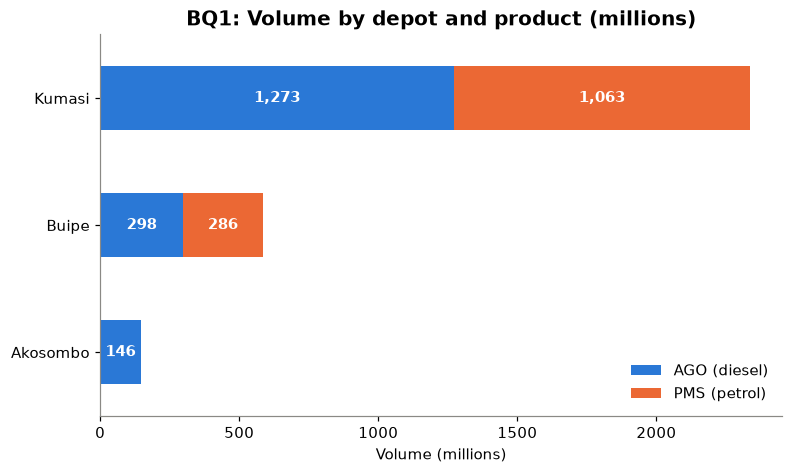

In [19]:
# Volume by depot, split into diesel and petrol
mix = pd.DataFrame({
    "AGO (diesel)": [clean["KSI_AGO"].sum(), clean["BUIPE_AGO"].sum(), clean["AKOSOMBO_AGO"].sum()],
    "PMS (petrol)": [clean["KSI_PMS"].sum(), clean["BUIPE_PMS"].sum(), 0],
}, index=["Kumasi", "Buipe", "Akosombo"]) / M
ax = mix.plot(kind="barh", stacked=True, color=[BLUE, ORANGE], title="BQ1: Volume by depot and product (millions)")
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:,.0f}" if v > 60 else "" for v in container.datavalues], label_type="center", color="white", fontweight="bold")
ax.invert_yaxis(); ax.set_xlabel("Volume (millions)")
plt.savefig("../images/nb_01_bq1_depot_product.png", bbox_inches="tight"); plt.show()

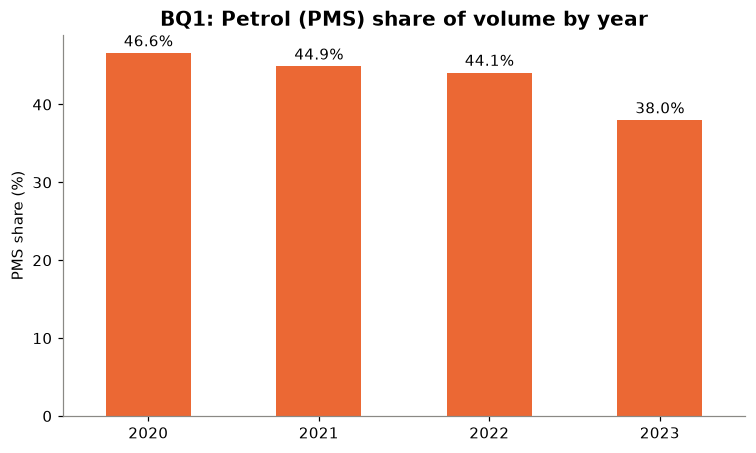

In [20]:
ax = by_year["PMS share %"].plot(kind="bar", color=ORANGE, title="BQ1: Petrol (PMS) share of volume by year")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
ax.set_ylabel("PMS share (%)"); ax.set_xlabel(""); plt.xticks(rotation=0)
plt.savefig("../images/nb_02_bq1_pms_share.png", bbox_inches="tight"); plt.show()

**Finding:** 3,065,382,800 moved over 916 report days. **Kumasi handles 76.2%** (2,335,377,300), Buipe 19.0% and Akosombo 4.8%. Diesel (AGO) is 56.0% of volume and petrol (PMS) 44.0%. The PMS share fell from 46.6% in 2020 to 38.0% in 2023, and Buipe transfers fell from 246.8M (2020) to 89.7M (2022).

**Recommendation:** Put Kumasi first in capacity and staffing plans. Investigate why Buipe transfers and the PMS share keep falling.

### BQ2 – Concentration among BDCs

In [21]:
bdc = clean.groupby("BDC")["Total"].sum().sort_values(ascending=False)
share = (bdc / bdc.sum() * 100).round(1)
print("Number of BDCs:", len(bdc))
print(f"Top-5 share: {bdc.head(5).sum() / bdc.sum():.1%}")
print(f"BOST + Juwel: {bdc.head(2).sum() / bdc.sum():.1%}")
share.head(10)

Number of BDCs: 21
Top-5 share: 68.4%
BOST + Juwel: 38.9%


BDC
BOST                                    19.8
Juwel                                   19.2
Goenergy                                11.4
Blue Ocean                              10.6
Cirrus                                   7.5
Chase Petroleum                          7.2
Vihama                                   5.5
Eagle Petroleum                          5.2
Dominion International Petroleum Ltd     4.0
Maranatha                                2.7
Name: Total, dtype: float64

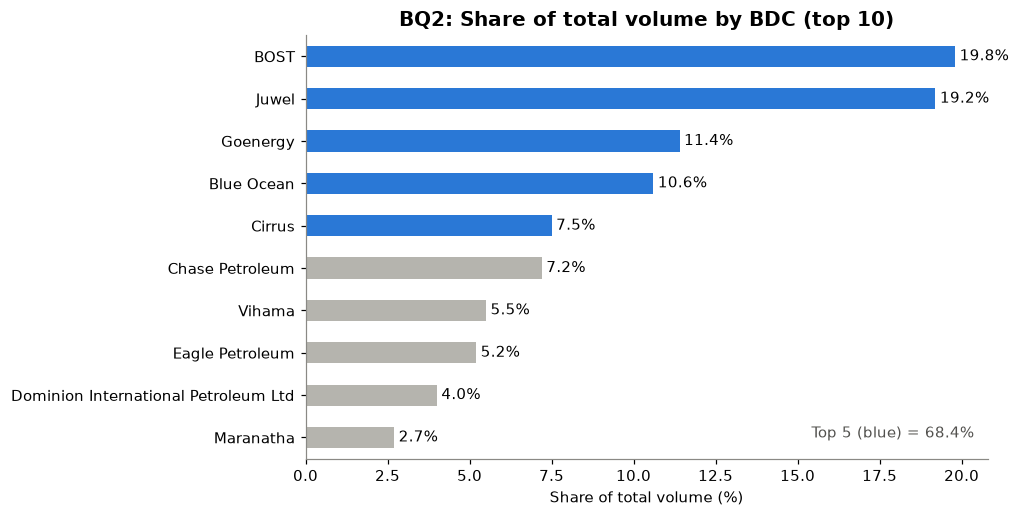

In [22]:
top = share.head(10)
ax = top.plot(kind="barh", color=[BLUE] * 5 + [GREY] * 5, figsize=(8, 5), title="BQ2: Share of total volume by BDC (top 10)")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3); ax.invert_yaxis()
ax.set_xlabel("Share of total volume (%)"); ax.set_ylabel("")
ax.text(0.98, 0.05, f"Top 5 (blue) = {bdc.head(5).sum() / bdc.sum():.1%}", transform=ax.transAxes, ha="right", color="#52514e")
plt.savefig("../images/nb_03_bq2_bdc_share.png", bbox_inches="tight"); plt.show()

**Finding:** 21 BDCs appear, but the **top 5 move 68.4%** of all volume: BOST, Juwel, Goenergy, Blue Ocean and Cirrus. BOST (19.8%) and Juwel (19.2%) alone account for 38.9%.

**Recommendation:** Track the top-5 share every month. Agree forward schedules with the two largest BDCs, since a disruption at either hits almost 40% of throughput.

### BQ3 – Trend

In [23]:
# Report days differ by month, so compare volume PER REPORT DAY
days = clean.groupby("Year")["Date"].nunique()
per_day = (by_year["Total"] / days).round(0)
print(pd.DataFrame({"report days": days, "volume": by_year["Total"], "per report day": per_day}))

# Jan-Aug totals, the period every year has
jan_aug = clean[clean["Date"].dt.month <= 8].groupby("Year")["Total"].sum()
print(jan_aug)

      report days     volume  per report day
Year                                        
2020          257  916616000       3566599.0
2021          245  891219800       3637632.0
2022          238  708719500       2977813.0
2023          176  548827500       3118338.0
Year
2020    593937000
2021    593475000
2022    499594000
2023    541209000
Name: Total, dtype: int64


In [24]:
# June 2023: diesel almost vanished
monthly = clean.groupby("Month")[["AGO_Total", "PMS_Total", "Total"]].sum()
print(monthly.loc[["2023-05", "2023-06", "2023-07"]])
june = clean[clean["Month"] == "2023-06"].groupby("Date")["AGO_Total"].sum()
print("June 2023 report days:", len(june), "| days with zero AGO:", (june == 0).sum())

         AGO_Total  PMS_Total     Total
Month                                  
2023-05   53206500   23519500  76726000
2023-06    6142500   37414500  43557000
2023-07   44990000   22029500  67019500
June 2023 report days: 21 | days with zero AGO: 14


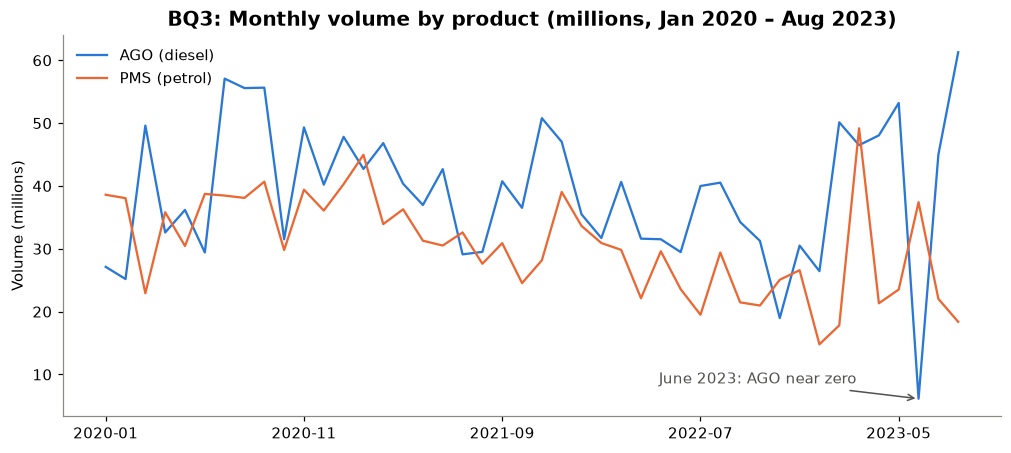

In [25]:
# September 2023 has only 2 report days, so leave that partial month out of the chart
full_months = monthly.loc[:"2023-08"]
ax = (full_months[["AGO_Total", "PMS_Total"]] / M).plot(color=[BLUE, ORANGE], figsize=(11, 4.5), title="BQ3: Monthly volume by product (millions, Jan 2020 – Aug 2023)")
ax.set_ylabel("Volume (millions)"); ax.set_xlabel(""); ax.legend(["AGO (diesel)", "PMS (petrol)"])
ax.annotate("June 2023: AGO near zero", xy=(list(full_months.index).index("2023-06"), full_months.loc["2023-06", "AGO_Total"] / M),
            xytext=(-170, 10), textcoords="offset points", arrowprops=dict(arrowstyle="->", color="#52514e"), color="#52514e")
plt.savefig("../images/nb_04_bq3_monthly_trend.png", bbox_inches="tight"); plt.show()

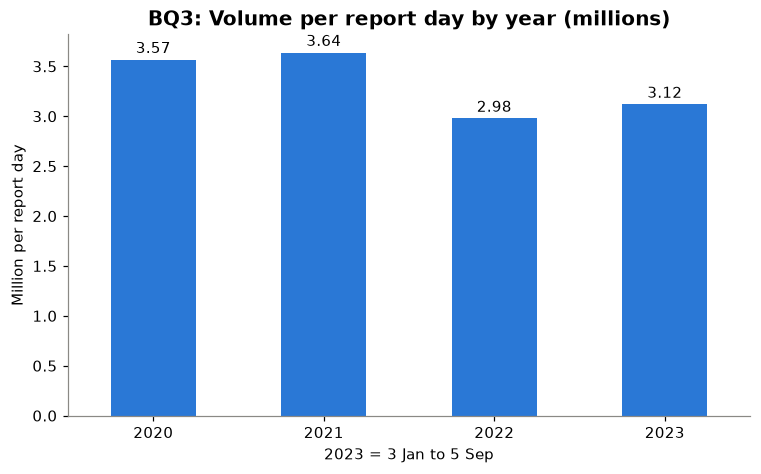

In [26]:
ax = (per_day / M).plot(kind="bar", color=BLUE, title="BQ3: Volume per report day by year (millions)")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=2)
ax.set_ylabel("Million per report day"); ax.set_xlabel("2023 = 3 Jan to 5 Sep"); plt.xticks(rotation=0)
plt.savefig("../images/nb_05_bq3_per_report_day.png", bbox_inches="tight"); plt.show()

**Finding:** Volume per report day was 3.57M (2020) and 3.64M (2021), dropped 18.1% to 2.98M in 2022, and recovered 4.7% to 3.12M in 2023 (to 5 Sep). Jan–Aug totals were 593.9M, 593.5M, 499.6M and 541.2M. **June 2023 is an outlier:** AGO fell to 6,142,500, against 53,206,500 in May and 44,990,000 in July, and AGO was zero on 14 of 21 report days.

**Recommendation:** Report trends per report day, since the number of report days per month varies. Investigate June 2023 and annotate it in the report so the dip is not misread.

### BQ4 – Customer shifts

In [27]:
bdc_year = clean.pivot_table(index="BDC", columns="Year", values="Total", aggfunc="sum", fill_value=0)
bdc_year_share = (bdc_year / bdc_year.sum() * 100).round(1)
print(bdc_year.loc[["BOST", "Blue Ocean", "Vihama", "Juwel"]])
print("BOST share by year (%):", bdc_year_share.loc["BOST"].to_dict())
print("BDCs with zero volume in 2023:", list(bdc_year[bdc_year[2023] == 0].index))
print(bdc_year.loc[["Chase Petroleum", "Lemla Petroleum", "Glorymay Petroleum Company Ltd", "Matrix Gas Ghana Limited"]])

Year             2020       2021       2022       2023
BDC                                                   
BOST         94882000  136819500   87933000  285980000
Blue Ocean  144402000  135247000   25078000   19307000
Vihama       69491500   57664500   35025500    5712500
Juwel       190560000  150049500  176098000   70377000
BOST share by year (%): {2020: 10.4, 2021: 15.4, 2022: 12.4, 2023: 52.1}
BDCs with zero volume in 2023: ['Chase Petroleum', 'Glorymay Petroleum Company Ltd', 'Lemla Petroleum', 'Matrix Gas Ghana Limited']
Year                                2020      2021      2022  2023
BDC                                                               
Chase Petroleum                 94072000  80776300  45047500     0
Lemla Petroleum                 41926500  10399000    270000     0
Glorymay Petroleum Company Ltd         0   2349000    540000     0
Matrix Gas Ghana Limited               0    590000         0     0


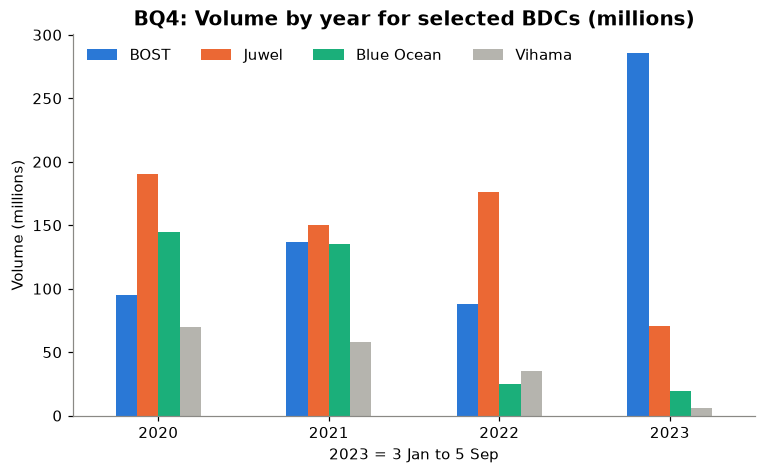

In [28]:
pick = (bdc_year.loc[["BOST", "Juwel", "Blue Ocean", "Vihama"]] / M).T
ax = pick.plot(kind="bar", color=[BLUE, ORANGE, AQUA, GREY], title="BQ4: Volume by year for selected BDCs (millions)")
ax.set_ylabel("Volume (millions)"); ax.set_xlabel("2023 = 3 Jan to 5 Sep"); plt.xticks(rotation=0); ax.legend(ncol=4, loc="upper left")
plt.savefig("../images/nb_06_bq4_bdc_by_year.png", bbox_inches="tight"); plt.show()

**Finding:** BOST's own volume jumped to 285,980,000 in 2023, **52.1% of the year**, up from 10–15% in 2020–2022. Blue Ocean fell from 135,247,000 (2021) to 19,307,000 (2023), and Vihama from 57,664,500 to 5,712,500. Chase Petroleum and Lemla Petroleum, both active earlier, moved nothing in 2023, nor did two small BDCs (Glorymay and Matrix Gas).

**Recommendation:** Find out why private BDCs are moving less (pricing, credit or supply), and whether BOST is filling the gap by design. Add a "no movement for 30 days" alert per BDC.

### BQ5 – Can management trust the Summary and Dashboard?

In [29]:
summary_total = summary.loc[summary["Row Labels"] == "Grand Total", summary.columns[1:]].sum(axis=1).iloc[0]
no_sheet = comb_only[vols].sum().sum()
missing_vol = clean[clean["SHEET"].str.strip().isin([d.strftime('%d-%m-%Y') for d in missing_days])]["Total"].sum()
print(f"Original Summary total:   {summary_total:,.0f}")
print(f"Missing from Combined:    {missing_vol:,.0f}")
print(f"Clean total:              {clean['Total'].sum():,.0f}")
print(f"Share of Summary volume with no source sheet: {no_sheet / summary_total:.1%}")

Original Summary total:   3,057,764,300
Missing from Combined:    7,618,500
Clean total:              3,065,382,800
Share of Summary volume with no source sheet: 20.2%


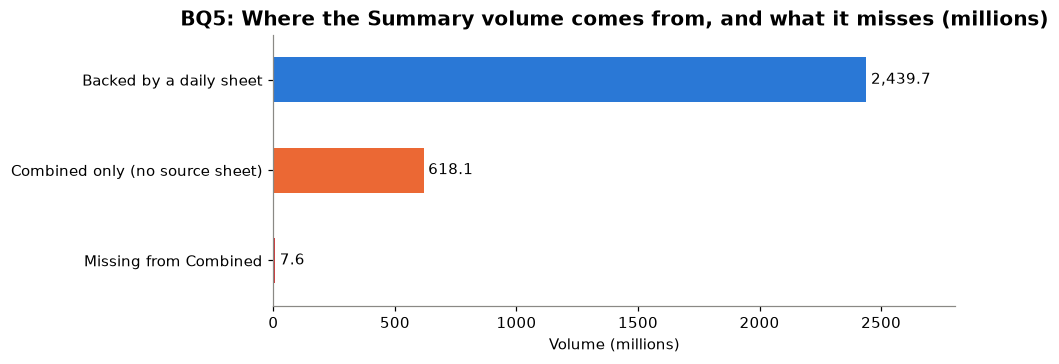

In [30]:
parts = pd.Series({"Backed by a daily sheet": (summary_total - no_sheet) / M,
                   "Combined only (no source sheet)": no_sheet / M,
                   "Missing from Combined": missing_vol / M})
ax = parts.plot(kind="barh", color=[BLUE, ORANGE, RED], figsize=(8, 3.2), title="BQ5: Where the Summary volume comes from, and what it misses (millions)")
ax.bar_label(ax.containers[0], labels=[f"{v:,.1f}" for v in parts], padding=3); ax.invert_yaxis(); ax.set_xlabel("Volume (millions)"); ax.set_ylabel("")
ax.set_xlim(0, parts.max() * 1.15)
plt.savefig("../images/nb_07_bq5_reliability.png", bbox_inches="tight"); plt.show()

**Finding:** No, not as it stands. The Summary and Dashboard read a Combined sheet last refreshed on 4 Sep 2023. They miss the last two daily sheets (7,618,500), and **20.2% of their volume has no source sheet** behind it. Nine sheets carry the wrong date, so their volume lands on the wrong day or month. The corrected total is 3,065,382,800, against 3,057,764,300 in the original Summary.

**Recommendation:** Refresh the query before every use (or set it to refresh on open) and show a "last refreshed" date. Derive G3 from the sheet name, or move to one data-entry table instead of 742 sheets. Keep the source sheet name in the query so every row can be traced.

## 6. Summary
| # | Question | Key number |
|---|---|---|
| BQ1 | Volume and mix | Kumasi **76.2%** of 3,065,382,800; PMS share 46.6% → 38.0% |
| BQ2 | Concentration | Top 5 BDCs move **68.4%**; BOST + Juwel 38.9% |
| BQ3 | Trend | Per report day 3.64M (2021) → 2.98M (2022) → 3.12M (2023); June 2023 AGO near zero |
| BQ4 | Customer shifts | BOST **52.1%** of 2023; Blue Ocean and Vihama down sharply |
| BQ5 | Reliability | Summary misses **7,618,500**; **20.2%** of its volume has no source sheet |

The rebuilt clean data (14,984 rows, 916 report days) matches the clean table in the Excel analysis workbook exactly.